# Phase 3 — Astronomical Data Dashboard

**Project:** Astronomical Object Classification Using Machine Learning  
**Dataset:** SDSS Stellar Classification (SDSS17)  
**Objective:** Prepare validated, analysis-ready CSV data sources and construct an interactive dashboard for exploring the distribution and photometric characteristics of stars, galaxies, and quasars.

## 1. Methodology

This notebook prepares the cleaned SDSS observations for a Looker Studio dashboard. The deliverables consist of a full-observation table, class statistics, band summaries, binned magnitude frequencies, and a stratified visualization sample. Each file has a distinct purpose so that dashboard totals are not accidentally calculated from sampled data.

A standalone interactive HTML dashboard is generated from these exports for local review and demonstration. No prediction models are trained during this phase.

In [29]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def locate_project_root():
    current = Path.cwd().resolve()
    for directory in (current, *current.parents):
        if (directory / "data" / "processed" / "sdss_cleaned.csv").exists():
            return directory
    raise FileNotFoundError("Cannot locate data/processed/sdss_cleaned.csv")


ROOT = locate_project_root()
DATA = ROOT / "data" / "processed"
DASHBOARD = ROOT / "dashboard"
FIGURES = ROOT / "figures" / "dashboard"
REPORTS = ROOT / "reports"

for directory in [DASHBOARD, FIGURES, REPORTS]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)


Project root: C:\Users\daksh\OneDrive\Desktop\ML Project\astronomy-ml-classification


## 2. Data loading and verification

The previous phase removed one row with invalid photometric values (the sentinel `-9999`). Before creating reporting tables, the cleaned file is checked for expected dimensions, class labels, missing magnitudes, and surviving invalid values.

In [30]:
required = ["alpha", "delta", "u", "g", "r", "i", "z", "class", "redshift"]
bands = ["u", "g", "r", "i", "z"]
classes = ["GALAXY", "STAR", "QSO"]

df = pd.read_csv(DATA / "sdss_cleaned.csv")
assert all(field in df.columns for field in required)
assert df.shape == (99_999, 18), "Unexpected input dimensions"
assert set(df["class"].unique()) == set(classes)
assert df[required].notna().all().all()
assert not df[bands].eq(-9999).any().any()

print("Observations:", len(df))
print("Original attributes:", df.shape[1])
print("Class distribution:")
print(df["class"].value_counts().reindex(classes).to_string())


Observations: 99999
Original attributes: 18
Class distribution:
class
GALAXY    59445
STAR      21593
QSO       18961


## 3. Deriving photometric colour indices

Colour indices are differences between pairs of apparent magnitudes. They describe relative brightness across filters and can reveal differences between the observed spectral profiles of astronomical object classes. These four fields are used here for visualization and will be formally assessed as candidate predictive features in Phase 4.

In [31]:
working = df[required].copy()
working["u_g"] = working["u"] - working["g"]
working["g_r"] = working["g"] - working["r"]
working["r_i"] = working["r"] - working["i"]
working["i_z"] = working["i"] - working["z"]
working.insert(0, "observation_id", np.arange(1, len(working) + 1))
working.insert(1, "observation_count", 1)

print(working.head(5).to_string(index=False))


 observation_id  observation_count      alpha     delta        u        g        r        i        z  class  redshift      u_g     g_r     r_i      i_z
              1                  1 135.689107 32.494632 23.87882 22.27530 20.39501 19.16573 18.79371 GALAXY  0.634794  1.60352 1.88029 1.22928  0.37202
              2                  1 144.826101 31.274185 24.77759 22.83188 22.58444 21.16812 21.61427 GALAXY  0.779136  1.94571 0.24744 1.41632 -0.44615
              3                  1 142.188790 35.582444 25.26307 22.66389 20.60976 19.34857 18.94827 GALAXY  0.644195  2.59918 2.05413 1.26119  0.40030
              4                  1 338.741038 -0.402828 22.13682 23.77656 21.61162 20.50454 19.25010 GALAXY  0.932346 -1.63974 2.16494 1.10708  1.25444
              5                  1 345.282593 21.183866 19.43718 17.58028 16.49747 15.97711 15.54461 GALAXY  0.116123  1.85690 1.08281 0.52036  0.43250


## 4. Full-observation reporting table

This table provides the **authoritative counts** for the dashboard. The sequential `observation_id` is created for reporting and must not be mistaken for a unique physical astronomical object identifier. Each record has `observation_count = 1`, enabling charts to use `SUM(observation_count)` without ambiguity.

For the main classification experiment, spectroscopic redshift remains excluded. It is included in this dashboard's exploratory table to permit a clearly labeled spectroscopy discussion.

In [32]:
full_columns = [
    "observation_id", "observation_count", "class", "alpha", "delta",
    "u", "g", "r", "i", "z", "u_g", "g_r", "r_i", "i_z", "redshift"
]
full_file = DASHBOARD / "looker_sdss_full.csv"
working[full_columns].to_csv(full_file, index=False, float_format="%.9g")
print("Full reporting table:", full_file.name)
print("Rows and columns:", working[full_columns].shape)


Full reporting table: looker_sdss_full.csv
Rows and columns: (99999, 15)


## 5. Class summary and percentages

All class counts and proportions are calculated from the full 99,999-row dataset. The class counts can serve as cross-checks when creating scorecards or stacked charts in Looker Studio.

In [33]:
class_summary = (
    working.groupby("class", observed=True)
    .agg(observations=("observation_count", "sum"))
    .reindex(classes)
    .reset_index()
)
class_summary["percentage"] = 100 * class_summary["observations"] / len(working)
class_summary.to_csv(DASHBOARD / "looker_class_summary.csv", index=False, float_format="%.6f")
print(class_summary.to_string(index=False, formatters={"percentage": "{:.2f}%".format}))


 class  observations percentage
GALAXY         59445     59.45%
  STAR         21593     21.59%
   QSO         18961     18.96%


## 6. Magnitude summary by filter and class

Each measurement is reshaped into a long-format table. Class-wise medians are preferable to means for describing the typical magnitude when distributions are skewed. A lower magnitude indicates greater observed flux in that band.

In [34]:
band_long = working.melt(
    id_vars=["observation_id", "class"],
    value_vars=bands,
    var_name="band",
    value_name="magnitude"
)
band_summary = (
    band_long.groupby(["class", "band"], observed=True)
    .agg(
        observations=("magnitude", "size"),
        mean=("magnitude", "mean"),
        median=("magnitude", "median"),
        std=("magnitude", "std"),
        p25=("magnitude", lambda x: x.quantile(0.25)),
        p75=("magnitude", lambda x: x.quantile(0.75)),
    )
    .reset_index()
)
band_summary["band"] = pd.Categorical(band_summary["band"], categories=bands, ordered=True)
band_summary["class"] = pd.Categorical(band_summary["class"], categories=classes, ordered=True)
band_summary = band_summary.sort_values(["class", "band"]).reset_index(drop=True)
band_summary["band"] = band_summary["band"].astype(str)
band_summary["class"] = band_summary["class"].astype(str)
band_summary.to_csv(DASHBOARD / "looker_band_summary.csv", index=False, float_format="%.6f")
print(band_summary[["class", "band", "median", "mean"]].round(3).to_string(index=False))


 class band  median   mean
GALAXY    u  22.842 22.587
GALAXY    g  21.582 20.906
GALAXY    r  20.105 19.588
GALAXY    i  19.224 18.852
GALAXY    z  18.767 18.449
  STAR    u  21.011 21.154
  STAR    g  19.543 19.617
  STAR    r  18.955 18.947
  STAR    i  18.592 18.544
  STAR    z  18.319 18.334
   QSO    u  21.503 21.548
   QSO    g  21.056 20.926
   QSO    r  20.773 20.624
   QSO    i  20.582 20.431
   QSO    z  20.374 20.267


## 7. Histogram bins for photometric measurements

A fixed bin width of 0.5 magnitude supports comparable histograms across the five filters. The resulting dataset contains counts for every class and band; no random sampling is involved.

In [35]:
bin_width = 0.5
band_long["bin_left"] = np.floor(band_long["magnitude"] / bin_width) * bin_width
band_long["bin_center"] = band_long["bin_left"] + bin_width / 2
histogram = (
    band_long.groupby(["band", "class", "bin_left", "bin_center"], observed=True)
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["band", "class", "bin_left"])
)
histogram.to_csv(DASHBOARD / "looker_magnitude_bins.csv", index=False, float_format="%.6f")
assert histogram["count"].sum() == 5 * len(working)
print("Histogram rows:", len(histogram))
print("Verified measurement counts:", histogram["count"].sum())


Histogram rows: 476
Verified measurement counts: 499995


## 8. Stratified sample for interactive scatter plots

Drawing all 99,999 observations on a browser scatter plot introduces considerable overplotting and browser load. A reproducible 9,000-row **balanced visualization sample** is therefore selected: 3,000 random observations from each class.

**Sampling limitation:** This sample intentionally changes class proportions. It is suitable for visual exploration of colour-space overlap and sky coverage, but not for estimating total class frequencies or the percentage of objects in each class.

In [36]:
sample_per_class = 3000
sample_parts = [
    working.loc[working["class"] == label].sample(n=sample_per_class, random_state=42)
    for label in classes
]
scatter_sample = (
    pd.concat(sample_parts, ignore_index=True)
    .sample(frac=1.0, random_state=42)
    .reset_index(drop=True)
)
scatter_sample[full_columns].to_csv(
    DASHBOARD / "looker_scatter_sample.csv", index=False, float_format="%.9g"
)
assert len(scatter_sample) == 9000
assert scatter_sample["class"].value_counts().eq(3000).all()
print("Visualization sample:", scatter_sample.shape)
print(scatter_sample["class"].value_counts().to_string())


Visualization sample: (9000, 15)
class
QSO       3000
GALAXY    3000
STAR      3000


## 9. Class frequency plot (complete dataset)

This graph uses all cleaned records. The GALAXY category is the majority class, so classification metrics in later phases should include macro-averaged F1-score and class-specific recall rather than only overall accuracy.

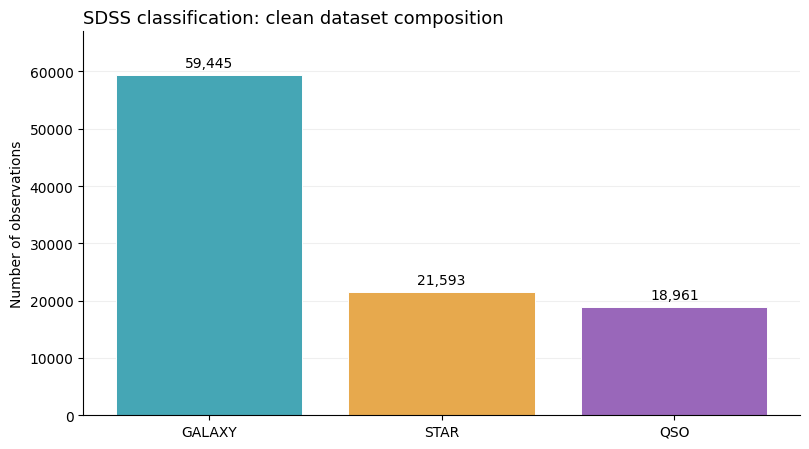

In [37]:
palette = {"GALAXY": "#45a6b5", "STAR": "#e7a94d", "QSO": "#9967ba"}
fig, ax = plt.subplots(figsize=(8.2, 4.6))
bars = ax.bar(
    class_summary["class"], class_summary["observations"],
    color=[palette[x] for x in class_summary["class"]], edgecolor="white", linewidth=0.7
)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 850,
            f"{b.get_height():,.0f}", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, 67000)
ax.set_ylabel("Number of observations")
ax.set_title("SDSS classification: clean dataset composition", loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "01_class_distribution.png", dpi=170)
plt.show()


## 10. Colour-colour scatter plot (visualization sample)

The colour-colour diagram illustrates how classes occupy overlapping regions of photometric feature space. The plot is descriptive rather than a trained decision boundary.

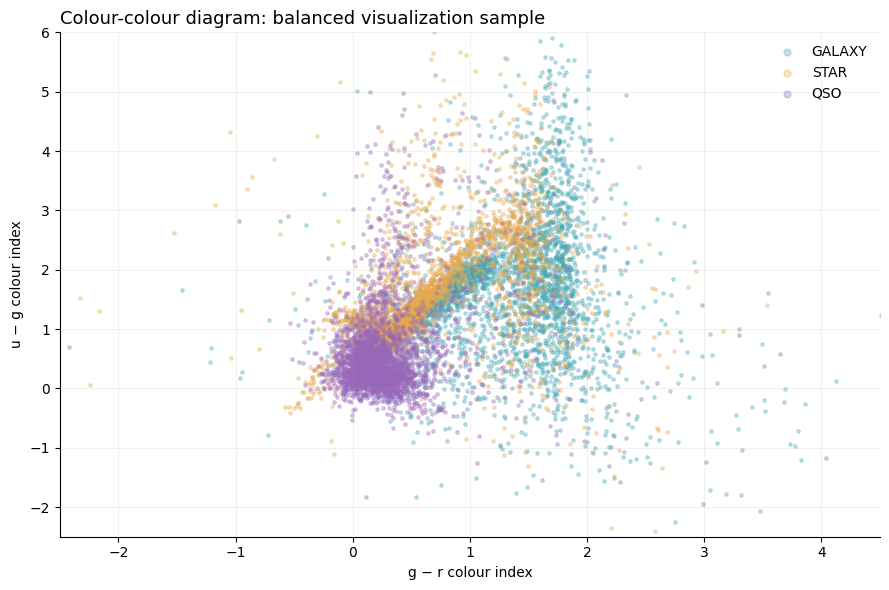

In [38]:
fig, ax = plt.subplots(figsize=(9, 6))
for label in classes:
    sub = scatter_sample.loc[scatter_sample["class"] == label]
    ax.scatter(sub["g_r"], sub["u_g"], s=6, alpha=.32, color=palette[label], label=label, rasterized=True)
ax.set_xlim(-2.5, 4.5)
ax.set_ylim(-2.5, 6)
ax.set_xlabel("g − r colour index")
ax.set_ylabel("u − g colour index")
ax.set_title("Colour-colour diagram: balanced visualization sample", loc="left", fontsize=13)
ax.legend(markerscale=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=.18)
fig.tight_layout()
fig.savefig(FIGURES / "02_colour_colour_diagram.png", dpi=170)
plt.show()


## 11. Build the local interactive dashboard

The standalone dashboard contains overview scorecards, full-population class charts, magnitude frequency graphs, colour-colour diagrams, sky coverage, and exploratory redshift distributions. Global class filters allow viewers to examine each category separately.

The interactive HTML contains the required JavaScript locally, so the report can be opened without a web server or an internet connection.

In [39]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from build_dashboard import build_dashboard

html_path = build_dashboard(ROOT)
print("Interactive dashboard:", html_path)
print("File size (MB):", round(html_path.stat().st_size / 1024**2, 2))


Interactive dashboard: C:\Users\daksh\OneDrive\Desktop\ML Project\astronomy-ml-classification\dashboard\SDSS_Interactive_Dashboard.html
File size (MB): 5.69


## 12. Final validation and handoff

The final checks ensure that reported class totals agree with the cleaned data, every band has the correct number of measurements, the balanced sample has the expected size, and all deliverable files exist.

In [40]:
assert class_summary["observations"].sum() == len(working)
assert len(band_summary) == len(classes) * len(bands)
assert (band_summary.groupby("band")["observations"].sum() == len(working)).all()
assert len(scatter_sample) == 9000
assert all((DASHBOARD / name).exists() for name in [
    "looker_sdss_full.csv", "looker_class_summary.csv", "looker_band_summary.csv",
    "looker_magnitude_bins.csv", "looker_scatter_sample.csv", "SDSS_Interactive_Dashboard.html"
])

validation = pd.DataFrame({
    "check": ["Cleaned observations", "Class categories", "Full records exported",
              "Histogram measurement total", "Visualization sample", "Dashboard generated"],
    "value": [len(working), len(classes), len(working), histogram["count"].sum(),
              len(scatter_sample), "Yes"],
    "result": ["PASS"] * 6
})
validation.to_csv(REPORTS / "phase3_validation.csv", index=False)
print(validation.to_string(index=False))
print("\nPhase 3 dataset preparation and local dashboard verification complete.")


                      check  value result
       Cleaned observations  99999   PASS
           Class categories      3   PASS
      Full records exported  99999   PASS
Histogram measurement total 499995   PASS
       Visualization sample   9000   PASS
        Dashboard generated    Yes   PASS

Phase 3 dataset preparation and local dashboard verification complete.


## 13. Analysis and conclusion

1. The cleaned SDSS dataset contains **99,999 observations** and **three spectroscopic class labels**: STAR, GALAXY, and QSO.
2. Class-frequency calculations use the full cleaned data. Galaxies are the largest class, so dashboard proportions must be derived from full records, not from the balanced scatter sample.
3. The five filter magnitudes provide different wavelength measurements. Their distributions and medians differ between classes, but they also overlap.
4. Colour indices provide a physically interpretable way to explore variations between the filter measurements. Separation in visual plots suggests directions for machine learning experiments but does not establish model accuracy.
5. Redshift is shown only for exploratory scientific interpretation; it is not part of the primary photometric feature set.
6. The Looker Studio data exports and offline dashboard are ready for reporting. A cloud-hosted Looker Studio report requires importing the CSVs into a Google account and sharing the resulting URL.

**Next phase:** Feature engineering, stratified train/test splitting, and leakage-safe preprocessing pipelines.